# Sharpening MODIS Land Cover from 500 m to 30 m for Switzerland (Machine Learning)

MODIS gives a land cover map for the whole world every year, but at 500 m a single pixel in Switzerland can contain
a village, a forest and a lake. In this notebook I use the 500 m MODIS map (2020) as a teacher and train a machine
learning model to recognise the same land cover classes from 30 m data:

- **Landsat 8:** NDVI (greenness), NDWI (water) and shortwave-infrared bands, summarised over the year (25th, 50th and 75th percentiles)
- **Sentinel-1 radar:** VV and VH backscatter (texture and structure, unaffected by clouds)
- **GHSL built-up surface:** how much of each pixel is covered by buildings
- **Elevation and slope:** essential in the Alps (added to my original script)

**What I improved from my original script**

- Fixed the Landsat scaling (Collection 2 Level-2 uses a fixed scale of 0.0000275 and offset of −0.2) and masked clouds.
- The model was given the MODIS label itself as an input, which leaks the answer; now only the real predictors are used.
- Training points are taken only where MODIS is **uniform over a 3×3 block of pixels**, so mixed 500 m pixels do not teach the model wrong labels.
- I switched from an untuned SVM to a **Random Forest** (no need to rescale inputs) and kept 30% of the points aside to measure how well
  the model agrees with MODIS, with a confusion matrix and the importance of each input.

**Outputs:** accuracy table, input importance, maps of the 500 m and 30 m land cover (whole country and a close-up),
area by class from both maps, and an optional export of the 30 m map to Google Drive.

> Ported from my original Earth Engine JavaScript (Code Editor) script.

## 1. Setup

Slow Earth Engine results (accuracy, areas and map images) are saved to `outputs/lc_switzerland/`, so
**Restart & Run All** after a restart is quick.

In [1]:
import os, io, json
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import requests
from PIL import Image
ee.Initialize(project="Your GEE username")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})

C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


## 2. Study area and settings

In [2]:
FIG_DIR, OUT_DIR = "figures/lc_switzerland", "outputs/lc_switzerland"
MAP_DIR = f"{OUT_DIR}/map_images"
for d in (FIG_DIR, OUT_DIR, MAP_DIR):
    os.makedirs(d, exist_ok=True)

COUNTRY = "Switzerland"
roi = (ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017").filter(ee.Filter.eq("country_na", COUNTRY))
         .map(lambda f: f.simplify(1200)).geometry())
ZOOM_BBOX = [8.10, 46.85, 8.60, 47.15]     # close-up around Lucerne: lakes, towns, forest and mountains

YEAR = 2020
N_PER_CLASS = 300       # training + test points per land cover class
TEST_SHARE = 0.3        # share of points kept aside to check the model
SAMPLE_SCALE = 100      # metres, as in my original script
N_TREES = 150
SEED = 42
RUN_EXPORT = False      # True = export the 30 m map to Google Drive (replaces nothing in the analysis)
FORCE_RECOMPUTE = False

# MODIS IGBP classes with the colours from my original script
IGBP = {1: "Evergreen needleleaf forest", 2: "Evergreen broadleaf forest", 3: "Deciduous needleleaf forest",
        4: "Deciduous broadleaf forest", 5: "Mixed forest", 6: "Closed shrubland", 7: "Open shrubland",
        8: "Woody savanna", 9: "Savanna", 10: "Grassland", 11: "Permanent wetland", 12: "Cropland",
        13: "Urban and built-up", 14: "Cropland/natural mosaic", 15: "Permanent snow and ice", 16: "Barren",
        17: "Water"}
PALETTE = ["05450a", "086a10", "54a708", "78d203", "009900", "c6b044", "dcd159", "dade48", "fbff13", "b6ff05",
           "27ff87", "c24f44", "a5a5a5", "ff6d4c", "69fff8", "f9ffa4", "1c0dff"]
VIS = {"min": 1, "max": 17, "palette": PALETTE}

## 3. The teacher map and the predictors

In [3]:
# 500 m MODIS land cover for the year (the labels the model learns from)
modis = (ee.ImageCollection("MODIS/061/MCD12Q1").select("LC_Type1")
           .filterDate(f"{YEAR}-01-01", f"{YEAR + 1}-01-01").first())

# Only keep MODIS pixels whose 3×3 neighbourhood has a single class ("pure" pixels)
uniform = (modis.reduceNeighborhood(ee.Reducer.countDistinct(), ee.Kernel.square(1))
                .reproject(modis.projection()).eq(1))
labels = modis.updateMask(uniform).rename("label")

# Landsat 8: correct Collection 2 scaling, clouds and shadows removed (snow is kept - it is a land cover class)
def landsat_indices(img):
    qa = img.select("QA_PIXEL")
    clear = qa.bitwiseAnd(0b11110).eq(0)      # bits 1-4: dilated cloud, cirrus, cloud, cloud shadow
    sr = img.select("SR_B.*").multiply(2.75e-05).add(-0.2).updateMask(clear)
    ndvi = sr.normalizedDifference(["SR_B5", "SR_B4"]).rename("ndvi")
    ndwi = sr.normalizedDifference(["SR_B3", "SR_B5"]).rename("ndwi")
    return ee.Image.cat([ndvi, ndwi, sr.select(["SR_B6", "SR_B7"])])

landsat = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
             .filterDate(f"{YEAR}-01-01", f"{YEAR + 1}-01-01").filterBounds(roi)
             .filter(ee.Filter.lt("CLOUD_COVER", 60)).map(landsat_indices))
landsat_stats = landsat.reduce(ee.Reducer.percentile([25, 50, 75]))   # how each pixel looks through the year

built = ee.Image("JRC/GHSL/P2023A/GHS_BUILT_S/2020").select("built_surface")

sar = (ee.ImageCollection("COPERNICUS/S1_GRD").filterDate(f"{YEAR}-01-01", f"{YEAR + 1}-01-01").filterBounds(roi)
         .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
         .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
         .filter(ee.Filter.eq("instrumentMode", "IW"))
         .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
         .select(["VV", "VH"]).mean())

dem = ee.Image("NASA/NASADEM_HGT/001").select("elevation")
terrain = ee.Image.cat([dem.rename("elevation"), ee.Terrain.slope(dem).rename("slope")])

predictors = ee.Image.cat([landsat_stats, built, sar, terrain]).float()
PREDICTOR_NAMES = predictors.bandNames().getInfo()
print(f"Landsat scenes: {landsat.size().getInfo()} | predictors: {len(PREDICTOR_NAMES)}")
print(PREDICTOR_NAMES)

Landsat scenes: 104 | predictors: 17
['ndvi_p25', 'ndvi_p50', 'ndvi_p75', 'ndwi_p25', 'ndwi_p50', 'ndwi_p75', 'SR_B6_p25', 'SR_B6_p50', 'SR_B6_p75', 'SR_B7_p25', 'SR_B7_p50', 'SR_B7_p75', 'built_surface', 'VV', 'VH', 'elevation', 'slope']


## 4. Training and checking the model

Points are drawn per class from the pure MODIS pixels. 70% train the Random Forest and 30% are used to check it.
The check measures **agreement with MODIS**, not true accuracy: where MODIS itself is wrong, the model learns the same mistake.

In [4]:
samples = (predictors.addBands(labels)
             .stratifiedSample(numPoints=N_PER_CLASS, classBand="label", region=roi, scale=SAMPLE_SCALE,
                               seed=SEED, tileScale=8, geometries=False)
             .randomColumn("split", SEED))
train = samples.filter(ee.Filter.lt("split", 1 - TEST_SHARE))
test = samples.filter(ee.Filter.gte("split", 1 - TEST_SHARE))

model = (ee.Classifier.smileRandomForest(numberOfTrees=N_TREES, seed=SEED)
           .train(features=train, classProperty="label", inputProperties=PREDICTOR_NAMES))

ACC_JSON = f"{OUT_DIR}/accuracy.json"
if os.path.exists(ACC_JSON) and not FORCE_RECOMPUTE:
    acc = json.load(open(ACC_JSON))
    print("Loaded saved accuracy results")
else:
    # The classes that actually have training points, in a fixed order for the confusion matrix
    class_counts = samples.aggregate_histogram("label").getInfo()
    class_order = sorted(int(float(k)) for k in class_counts)
    matrix = test.classify(model).errorMatrix("label", "classification", class_order)
    acc = ee.Dictionary({
        "overall": matrix.accuracy(), "kappa": matrix.kappa(),
        "matrix": matrix.array(), "order": class_order,
        "producers": matrix.producersAccuracy(), "consumers": matrix.consumersAccuracy(),
        "importance": model.explain().get("importance"),
    }).getInfo()
    acc["class_counts"] = {str(int(float(k))): v for k, v in class_counts.items()}
    json.dump(acc, open(ACC_JSON, "w"))

order = acc["order"]
names = [IGBP[int(k)] for k in order]
per_class = pd.DataFrame({
    "Class": names,
    "Points": [acc["class_counts"].get(str(int(k)), 0) for k in order],
    "Producer's accuracy": np.ravel(acc["producers"])[:len(order)],
    "User's accuracy": np.ravel(acc["consumers"])[:len(order)],
}).set_index("Class")
per_class["F1"] = (2 * per_class["Producer's accuracy"] * per_class["User's accuracy"]
                   / (per_class["Producer's accuracy"] + per_class["User's accuracy"]))
per_class.round(3).to_csv(f"{OUT_DIR}/accuracy_by_class.csv")
print(f"Overall agreement with MODIS: {acc['overall']:.1%} | kappa: {acc['kappa']:.3f}")
per_class.round(2)

Overall agreement with MODIS: 72.6% | kappa: 0.701


,Points,Producer's accuracy,User's accuracy,F1
Class,,,,
Evergreen needleleaf forest,300,0.86,0.84,0.85
Deciduous broadleaf forest,300,0.76,0.73,0.75
Mixed forest,300,0.68,0.57,0.62
Woody savanna,300,0.55,0.68,0.61
Savanna,300,0.41,0.47,0.44
Grassland,300,0.84,0.86,0.85
Cropland,300,0.72,0.61,0.66
Urban and built-up,300,0.75,0.68,0.71
Cropland/natural mosaic,300,0.46,0.58,0.51


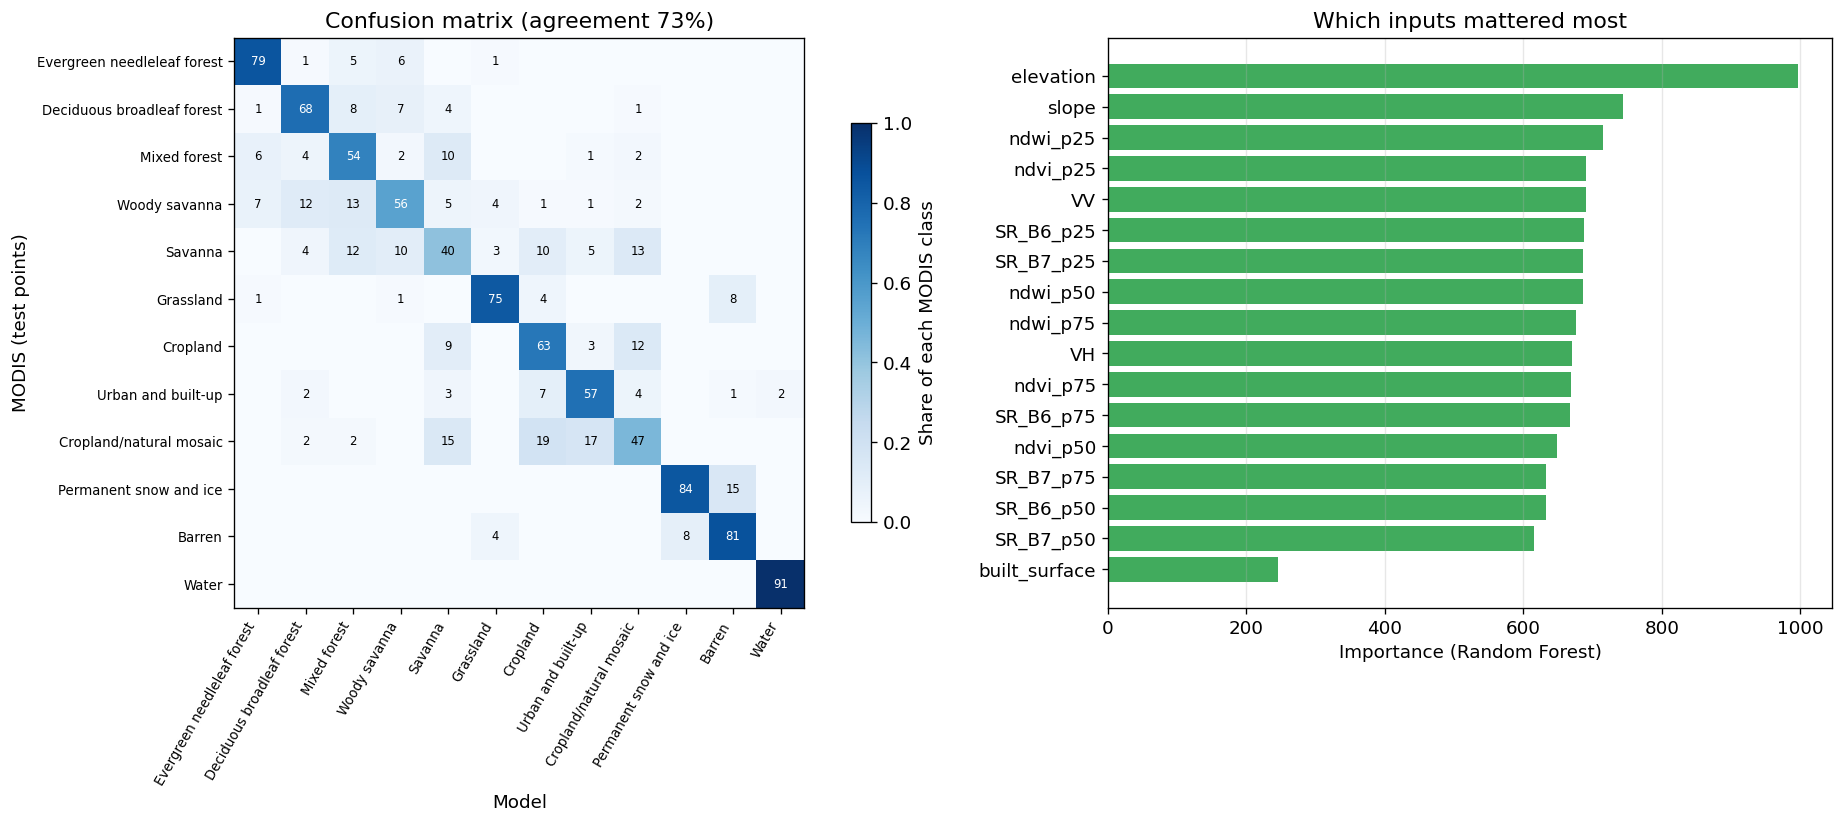

In [5]:
cm = np.array(acc["matrix"], dtype=float)
cm_share = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
importance = pd.Series(acc["importance"]).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.3, 1]})
im = ax1.imshow(cm_share, cmap="Blues", vmin=0, vmax=1)
ax1.set_xticks(range(len(names))); ax1.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
ax1.set_yticks(range(len(names))); ax1.set_yticklabels(names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        if cm[i, j] > 0:
            ax1.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                     color="white" if cm_share[i, j] > 0.5 else "black")
ax1.set(xlabel="Model", ylabel="MODIS (test points)", title=f"Confusion matrix (agreement {acc['overall']:.0%})")
fig.colorbar(im, ax=ax1, shrink=0.7, label="Share of each MODIS class")
ax2.barh(importance.index, importance.values, color="#41ab5d")
ax2.set(xlabel="Importance (Random Forest)", title="Which inputs mattered most"); ax2.grid(axis="x", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_accuracy_and_importance.png"); plt.show()

## 5. The 30 m land cover map

  model_30m_zoom at 1400px failed (400 Client Error: Bad Request for url: https://earthengine.g), trying smaller


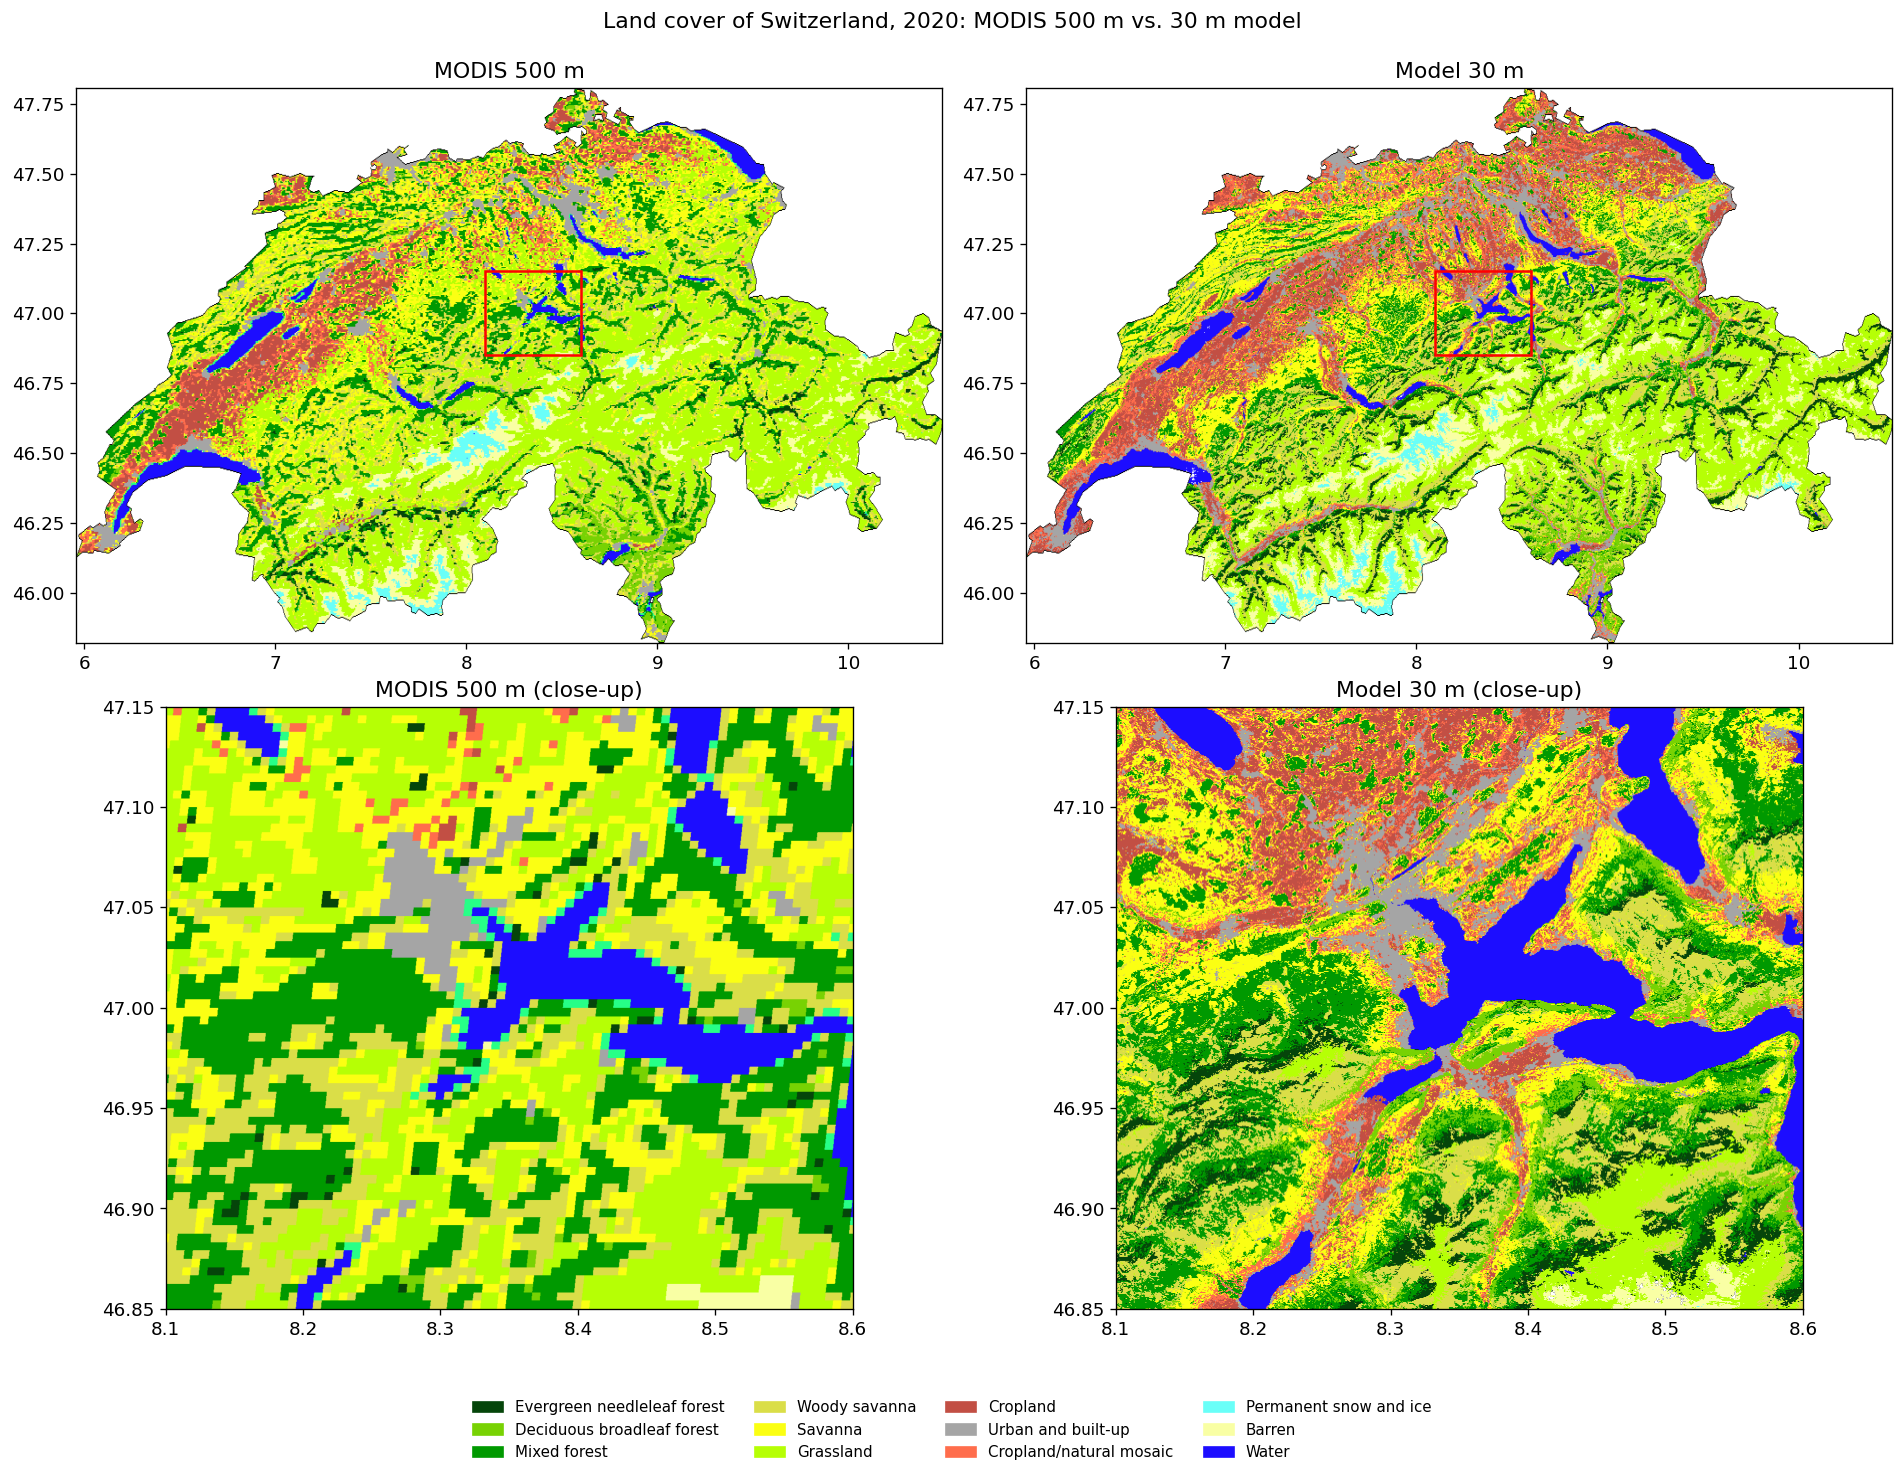

In [6]:
lc30 = predictors.classify(model).rename("lc30").clip(roi)

def thumb(key, vis_image, region, dims=1400):
    path = f"{MAP_DIR}/{key}.png"
    if os.path.exists(path) and not FORCE_RECOMPUTE:
        return np.array(Image.open(path))
    for size in (dims, 1000, 700):
        try:
            url = vis_image.getThumbURL({"region": region, "dimensions": size, "crs": "EPSG:4326", "format": "png"})
            resp = requests.get(url, timeout=600); resp.raise_for_status()
            img = Image.open(io.BytesIO(resp.content)); img.save(path)
            return np.array(img)
        except Exception as e:
            print(f"  {key} at {size}px failed ({str(e)[:60]}), trying smaller")
    raise RuntimeError(f"Could not render {key}")

white = ee.Image(1).visualize(palette=["ffffff"])
border = ee.Image().byte().paint(ee.FeatureCollection([ee.Feature(roi)]), 1, 1).visualize(palette=["000000"])
zoom = ee.Geometry.Rectangle(ZOOM_BBOX)
b = np.array(roi.bounds().coordinates().getInfo()[0])
ch_extent = [b[:, 0].min(), b[:, 0].max(), b[:, 1].min(), b[:, 1].max()]
zoom_extent = [ZOOM_BBOX[0], ZOOM_BBOX[2], ZOOM_BBOX[1], ZOOM_BBOX[3]]

panels = [
    (thumb("modis_500m", white.blend(modis.clip(roi).visualize(**VIS)).blend(border), roi.bounds()), "MODIS 500 m", ch_extent),
    (thumb("model_30m", white.blend(lc30.visualize(**VIS)).blend(border), roi.bounds()), "Model 30 m", ch_extent),
    (thumb("modis_500m_zoom", modis.visualize(**VIS), zoom), "MODIS 500 m (close-up)", zoom_extent),
    (thumb("model_30m_zoom", lc30.visualize(**VIS), zoom), "Model 30 m (close-up)", zoom_extent),
]
present = sorted(set(int(k) for k in order))
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, (arr, title, ext) in zip(axes.flat, panels):
    ax.imshow(arr, extent=ext); ax.set_title(title); ax.set_aspect(1 / np.cos(np.deg2rad(46.8)))
z = ZOOM_BBOX
for ax in axes[0]:
    ax.add_patch(mpatches.Rectangle((z[0], z[1]), z[2] - z[0], z[3] - z[1], fill=False, ec="red", lw=1.5))
fig.legend(handles=[mpatches.Patch(color="#" + PALETTE[k - 1], label=IGBP[k]) for k in present],
           loc="lower center", ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f"Land cover of {COUNTRY}, {YEAR}: MODIS 500 m vs. 30 m model", y=0.995)
fig.tight_layout(rect=[0, 0.06, 1, 1]); fig.savefig(f"{FIG_DIR}/02_land_cover_maps.png", bbox_inches="tight"); plt.show()

## 6. Area of each class: MODIS vs. the 30 m model

The country is measured in tiles at 100 m and each tile is saved, so a time-out only costs one tile (run again to finish).

tile 0_0: done
tile 0_1: done
tile 0_2: done
tile 1_0: done
tile 1_1: done
tile 1_2: done
tile 2_0: done
tile 2_1: done
tile 2_2: done


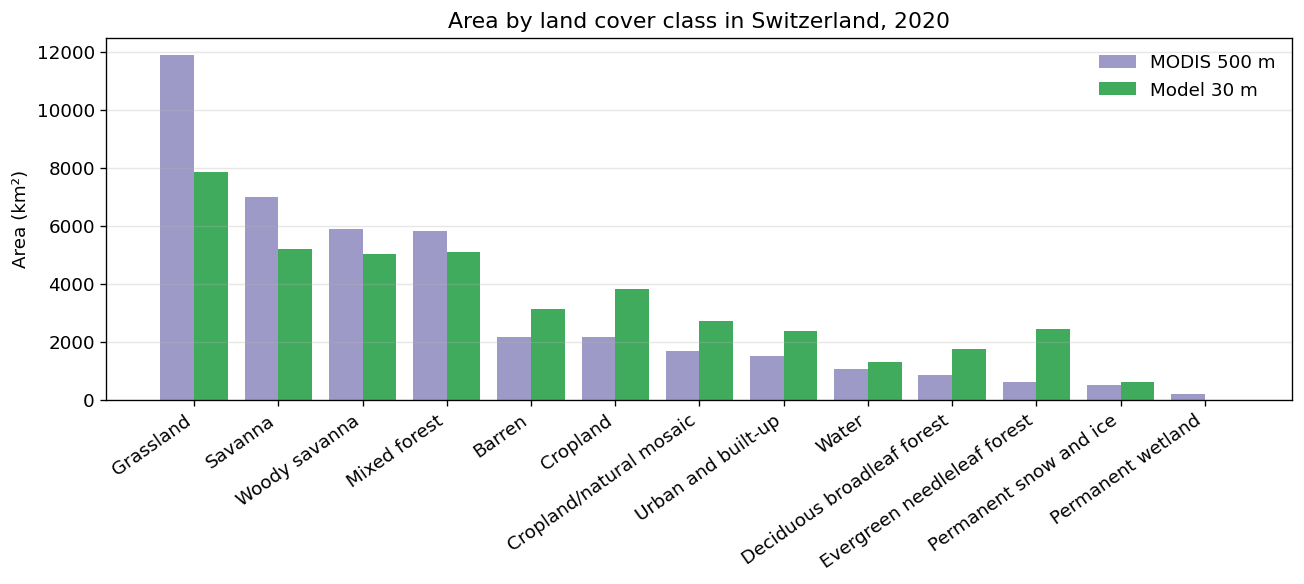

,MODIS 500 m (km²),Model 30 m (km²),Difference (km²)
Grassland,11894.0,7846.0,-4048.0
Savanna,7000.0,5190.0,-1810.0
Woody savanna,5880.0,5025.0,-855.0
Mixed forest,5803.0,5080.0,-723.0
Barren,2150.0,3114.0,965.0
Cropland,2147.0,3802.0,1655.0
Cropland/natural mosaic,1679.0,2716.0,1036.0
Urban and built-up,1513.0,2355.0,842.0
Water,1051.0,1314.0,263.0
Deciduous broadleaf forest,856.0,1757.0,901.0


In [7]:
AREA_JSON = f"{OUT_DIR}/area_tiles.json"
TILES_N = 3
px = ee.Image.pixelArea().divide(1e6)
x_edges = np.linspace(ch_extent[0], ch_extent[1], TILES_N + 1)
y_edges = np.linspace(ch_extent[2], ch_extent[3], TILES_N + 1)
group = ee.Reducer.sum().group(groupField=1, groupName="class")

done = json.load(open(AREA_JSON)) if os.path.exists(AREA_JSON) and not FORCE_RECOMPUTE else {}
for i in range(TILES_N):
    for j in range(TILES_N):
        key = f"{i}_{j}"
        if key in done:
            continue
        tile = ee.Geometry.Rectangle([x_edges[i], y_edges[j], x_edges[i + 1], y_edges[j + 1]]).intersection(roi, 1)
        try:
            done[key] = ee.Dictionary({
                "modis": px.addBands(modis).reduceRegion(group, tile, 500, maxPixels=1e13).get("groups"),
                "model": px.addBands(lc30).reduceRegion(group, tile, 100, maxPixels=1e13, tileScale=16).get("groups"),
            }).getInfo()
            json.dump(done, open(AREA_JSON, "w"))
            print(f"tile {key}: done")
        except ee.EEException as e:
            print(f"tile {key}: {str(e)[:60]} - run the cell again")

def total(source):
    rows = [g for t in done.values() for g in (t[source] or [])]
    return pd.DataFrame(rows).groupby("class")["sum"].sum() if rows else pd.Series(dtype=float)

areas = pd.DataFrame({"MODIS 500 m (km²)": total("modis"), "Model 30 m (km²)": total("model")}).fillna(0)
areas.index = [IGBP[int(k)] for k in areas.index]
areas["Difference (km²)"] = areas["Model 30 m (km²)"] - areas["MODIS 500 m (km²)"]
areas = areas.sort_values("MODIS 500 m (km²)", ascending=False)
areas.round(1).to_csv(f"{OUT_DIR}/area_by_class.csv")

top = areas[(areas.iloc[:, :2] > 50).any(axis=1)]
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(top))
ax.bar(x - 0.2, top["MODIS 500 m (km²)"], 0.4, color="#9e9ac8", label="MODIS 500 m")
ax.bar(x + 0.2, top["Model 30 m (km²)"], 0.4, color="#41ab5d", label="Model 30 m")
ax.set_xticks(x); ax.set_xticklabels(top.index, rotation=35, ha="right")
ax.set(ylabel="Area (km²)", title=f"Area by land cover class in {COUNTRY}, {YEAR}")
ax.legend(frameon=False); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_area_by_class.png"); plt.show()
areas.round(0)

## 7. Optional: export the 30 m map

A 30 m map of the whole country is too large to download directly, so (like my original script) it is exported to
Google Drive. Set `RUN_EXPORT = True` in Section 2 and follow the task in the Earth Engine **Tasks** page.

In [8]:
if RUN_EXPORT:
    task = ee.batch.Export.image.toDrive(image=lc30.toByte(), description=f"landcover_30m_{COUNTRY}_{YEAR}",
                                         folder="earthengine", region=roi.bounds(), scale=30, crs="EPSG:4326",
                                         maxPixels=1e13)
    task.start()
    print("Export started:", task.status()["state"])
else:
    print("Export skipped (set RUN_EXPORT = True to export the 30 m map to Google Drive).")

Export skipped (set RUN_EXPORT = True to export the 30 m map to Google Drive).


## 8. Notes

- **Data:** MODIS MCD12Q1 v6.1 (Friedl & Sulla-Menashe 2022); Landsat 8 Collection 2 Level-2; Sentinel-1 GRD;
  GHSL built-up surface 2020 (Pesaresi & Politis 2023); NASADEM; US State Department LSIB boundaries.
- The model can only be as good as its teacher. MODIS's IGBP classes were designed for global 500 m mapping and do not
  separate Swiss land cover types well (e.g. alpine meadows vs. cropland). For a reference map, compare with the Swiss
  Federal Statistical Office land use statistics (Arealstatistik) or ESA WorldCover (10 m).
- Agreement on the test points is measured on uniform MODIS pixels, which are easier than mixed areas, so it is an
  optimistic measure.
- Rare classes (only a few pure MODIS pixels in Switzerland) get fewer training points and are less reliable.